# pandas Basics: A Revision Notebook

pandas is the Python library for working with **tables of data**: rows and columns with names, like a spreadsheet.
It's usually the first tool you use on a new dataset. You load it, look at it and clean it, then hand the numbers to NumPy or a model.

**How to use this notebook**

- Read each text cell, then run the code cell under it (**Shift + Enter**).
- A table on the last line of a cell is shown automatically, so many cells end with just `df` or `df.head()`.
- Change things and run again to see what happens.
- Run the cells **from top to bottom**, because later cells use the table made earlier.

**Contents**

1. Import
2. Series and DataFrame
3. Making a DataFrame and reading a CSV file
4. First look at the data
5. Picking columns
6. Picking rows: `iloc` and `loc`
7. Filtering rows with conditions
8. Adding, renaming and removing columns
9. Sorting
10. Missing values
11. Counting and grouping
12. Text categories to numbers
13. Applying your own function: `apply`
14. Joining tables: `concat` and `merge`
15. From pandas to NumPy, ready for a model
16. Quick plots
17. Cheat sheet

## 1. Import

`pd` is the usual short name for pandas. NumPy usually comes along too.

In [1]:
import numpy as np
import pandas as pd

## 2. Series and DataFrame

pandas has two main things:

| Name | What it is | Picture |
|---|---|---|
| **Series** | one column of values, each with a label (the **index**) | a single column |
| **DataFrame** | a table: several Series side by side, sharing the same index | a whole spreadsheet |

```
DataFrame
         size  bedrooms  price      <- column names
    0    2104         5    460
    1    1416         3    232      <- each column is a Series
    2     852         2    178
    ^
  index (row labels)
```

In [2]:
s = pd.Series([460, 232, 178], name="price")
s

0    460
1    232
2    178
Name: price, dtype: int64

## 3. Making a DataFrame and reading a CSV file

### From a dictionary

Each **key** becomes a column name, and each **list** becomes that column's values. All the lists must be the same length.

We'll use this small housing table for the rest of the notebook. `np.nan` means "missing value".

In [3]:
df = pd.DataFrame({
    "size":     [2104, 1416, 852, 1940, 1534, 1200],
    "bedrooms": [5, 3, 2, 4, 3, np.nan],
    "floors":   [1, 2, 1, 2, 1, 1],
    "age":      [45, 40, 35, 12, 30, 8],
    "city":     ["Pune", "Delhi", "Pune", "Mumbai", "Delhi", "Pune"],
    "price":    [460, 232, 178, 540, 315, 250],
})
df

,size,bedrooms,floors,age,city,price
0,2104,5.0,1,45,Pune,460
1,1416,3.0,2,40,Delhi,232
2,852,2.0,1,35,Pune,178
3,1940,4.0,2,12,Mumbai,540
4,1534,3.0,1,30,Delhi,315
5,1200,NaN,1,8,Pune,250


### From a CSV file

Real data usually comes as a **CSV file** (comma-separated values). It reads into a DataFrame in one line:

```python
df = pd.read_csv("houses.csv")
```

Here's a working example that writes a small CSV file, reads it back, then deletes it:

In [4]:
import os

df.to_csv("houses_demo.csv", index=False)   # save the table to a file (index=False: don't save row numbers)

loaded = pd.read_csv("houses_demo.csv")     # read it back
print(loaded.shape)                          # (6, 6)
os.remove("houses_demo.csv")                 # clean up the demo file

(6, 6)


## 4. First look at the data

These are the first things to run on any new dataset:

| Code | Shows |
|---|---|
| `df.head()` / `df.tail()` | first / last 5 rows (`df.head(3)` for 3) |
| `df.shape` | `(rows, columns)` |
| `df.columns` | the column names |
| `df.dtypes` | the type of each column |
| `df.info()` | columns, types and how many values are **not** missing |
| `df.describe()` | count, mean, min, max, ... for each number column |

In [5]:
df.head(3)

,size,bedrooms,floors,age,city,price
0,2104,5.0,1,45,Pune,460
1,1416,3.0,2,40,Delhi,232
2,852,2.0,1,35,Pune,178


In [6]:
print(df.shape)            # (6, 6) -> 6 rows, 6 columns
print(list(df.columns))    # ['size', 'bedrooms', 'floors', 'age', 'city', 'price']

(6, 6)
['size', 'bedrooms', 'floors', 'age', 'city', 'price']


In [7]:
df.info()   # look at bedrooms: 5 non-null out of 6 -> one value is missing

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   size      6 non-null      int64  
 1   bedrooms  5 non-null      float64
 2   floors    6 non-null      int64  
 3   age       6 non-null      int64  
 4   city      6 non-null      str    
 5   price     6 non-null      int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 420.0 bytes


In [8]:
df.describe()   # 50% is the median (the middle value)

,size,bedrooms,floors,age,price
count,6.000000,5.000000,6.000000,6.000000,6.000000
mean,1507.666667,3.400000,1.333333,28.333333,329.166667
std,463.935197,1.140175,0.516398,15.108497,141.653686
min,852.000000,2.000000,1.000000,8.000000,178.000000
25%,1254.000000,3.000000,1.000000,16.500000,236.500000
50%,1475.000000,3.000000,1.000000,32.500000,282.500000
75%,1838.500000,4.000000,1.750000,38.750000,423.750000
max,2104.000000,5.000000,2.000000,45.000000,540.000000


**Types you'll see:** `int64` = whole numbers, `float64` = decimals, and `str` or `object` = text.
The `bedrooms` column is `float64` even though bedrooms are whole numbers, because a column with a missing value (`NaN`) is stored as decimals.

## 5. Picking columns

| Code | Gives |
|---|---|
| `df["price"]` | **one** column, as a Series |
| `df[["size", "price"]]` | **several** columns, as a DataFrame. Note the **double** brackets: the inner `[ ]` is a list of names |

In [9]:
df["price"]

0    460
1    232
2    178
3    540
4    315
5    250
Name: price, dtype: int64

In [10]:
df[["size", "price"]]

,size,price
0,2104,460
1,1416,232
2,852,178
3,1940,540
4,1534,315
5,1200,250


A Series has the same summary methods as a NumPy array:

In [11]:
print(df["price"].mean())   # 329.1666666666667
print(df["price"].max())    # 540
print(df["size"].min())     # 852

329.1666666666667
540
852


## 6. Picking rows: `iloc` and `loc`

| Code | Picks by... | Example |
|---|---|---|
| `df.iloc[...]` | **position** (0, 1, 2, ...), like NumPy | `df.iloc[0]` = first row |
| `df.loc[...]` | **label** (index value or column name) | `df.loc[0, "price"]` |

Both take `[rows, columns]`, like a 2D NumPy array.

The big difference: an `iloc` slice **stops before** the end, but a `loc` slice **includes** the end.

In [12]:
df.iloc[0]          # first row, as a Series

size        2104
bedrooms     5.0
floors         1
age           45
city        Pune
price        460
Name: 0, dtype: object

In [13]:
print(df.iloc[0, 5])        # 460 -> row 0, column 5 (price)
print(df.loc[0, "price"])   # 460 -> same thing, by name

df.iloc[1:3]                # rows 1 and 2 (stops before 3)

460
460


,size,bedrooms,floors,age,city,price
1,1416,3.0,2,40,Delhi,232
2,852,2.0,1,35,Pune,178


In [14]:
df.loc[1:3, ["size", "price"]]   # rows 1, 2 AND 3 (loc includes the end), two columns

,size,price
1,1416,232
2,852,178
3,1940,540


## 7. Filtering rows with conditions

This works just like NumPy masks: the condition makes a True/False for every row, and `df[mask]` keeps the True rows.

In [15]:
df["price"] > 300     # True/False for each row

0     True
1    False
2    False
3     True
4     True
5    False
Name: price, dtype: bool

In [16]:
df[df["price"] > 300]   # only the rows where price > 300

,size,bedrooms,floors,age,city,price
0,2104,5.0,1,45,Pune,460
3,1940,4.0,2,12,Mumbai,540
4,1534,3.0,1,30,Delhi,315


### Combining conditions

| Python normally | In pandas |
|---|---|
| `and` | `&` |
| `or` | `\|` |
| `not` | `~` |

Put **each condition in brackets**, otherwise you'll get an error.

`.isin([...])` checks "is it one of these?".

In [17]:
df[(df["city"] == "Pune") & (df["age"] < 40)]

,size,bedrooms,floors,age,city,price
2,852,2.0,1,35,Pune,178
5,1200,NaN,1,8,Pune,250


In [18]:
df[df["city"].isin(["Delhi", "Mumbai"])]

,size,bedrooms,floors,age,city,price
1,1416,3.0,2,40,Delhi,232
3,1940,4.0,2,12,Mumbai,540
4,1534,3.0,1,30,Delhi,315


## 8. Adding, renaming and removing columns

- **Add** a column by assigning to a new name. The math is applied to every row, like with NumPy.
- **Rename** with `rename(columns={"old": "new"})`.
- **Remove** with `drop(columns=[...])`.

`rename` and `drop` give back a **new** table and leave `df` unchanged. To keep the result, assign it: `df = df.drop(...)`.

In [19]:
df["price_per_sqft"] = df["price"] * 1000 / df["size"]   # new column from two others
df.head(3)

,size,bedrooms,floors,age,city,price,price_per_sqft
0,2104,5.0,1,45,Pune,460,218.631179
1,1416,3.0,2,40,Delhi,232,163.841808
2,852,2.0,1,35,Pune,178,208.920188


In [20]:
df.rename(columns={"size": "size_sqft"}).head(2)   # df itself is unchanged

,size_sqft,bedrooms,floors,age,city,price,price_per_sqft
0,2104,5.0,1,45,Pune,460,218.631179
1,1416,3.0,2,40,Delhi,232,163.841808


In [21]:
df = df.drop(columns=["price_per_sqft"])   # assign back to keep the change
list(df.columns)

['size', 'bedrooms', 'floors', 'age', 'city', 'price']

## 9. Sorting

`sort_values("column")` sorts the rows by that column, smallest first. Add `ascending=False` for biggest first.

In [22]:
df.sort_values("price", ascending=False)

,size,bedrooms,floors,age,city,price
3,1940,4.0,2,12,Mumbai,540
0,2104,5.0,1,45,Pune,460
4,1534,3.0,1,30,Delhi,315
5,1200,NaN,1,8,Pune,250
1,1416,3.0,2,40,Delhi,232
2,852,2.0,1,35,Pune,178


Notice the index (left side) keeps each row's original label. `reset_index(drop=True)` renumbers the rows 0, 1, 2, ...

In [23]:
df.sort_values("price").reset_index(drop=True)

,size,bedrooms,floors,age,city,price
0,852,2.0,1,35,Pune,178
1,1416,3.0,2,40,Delhi,232
2,1200,NaN,1,8,Pune,250
3,1534,3.0,1,30,Delhi,315
4,2104,5.0,1,45,Pune,460
5,1940,4.0,2,12,Mumbai,540


## 10. Missing values

Real data almost always has gaps. pandas shows a missing value as `NaN`.

| Code | Does |
|---|---|
| `df.isna()` | True where a value is missing |
| `df.isna().sum()` | **how many** are missing in each column (True counts as 1) |
| `df.dropna()` | removes rows that have any missing value |
| `df["col"].fillna(value)` | fills the gaps in a column with `value` |

In [24]:
df.isna().sum()   # bedrooms: 1

size        0
bedrooms    1
floors      0
age         0
city        0
price       0
dtype: int64

In [25]:
df.dropna()       # row 5 is gone

,size,bedrooms,floors,age,city,price
0,2104,5.0,1,45,Pune,460
1,1416,3.0,2,40,Delhi,232
2,852,2.0,1,35,Pune,178
3,1940,4.0,2,12,Mumbai,540
4,1534,3.0,1,30,Delhi,315


In [26]:
median_bedrooms = df["bedrooms"].median()
df["bedrooms"] = df["bedrooms"].fillna(median_bedrooms)   # fill the gap with the middle value
df

,size,bedrooms,floors,age,city,price
0,2104,5.0,1,45,Pune,460
1,1416,3.0,2,40,Delhi,232
2,852,2.0,1,35,Pune,178
3,1940,4.0,2,12,Mumbai,540
4,1534,3.0,1,30,Delhi,315
5,1200,3.0,1,8,Pune,250


Filling with the **median** (middle value) or the **mean** (average) is common. It keeps the row instead of throwing it away.

## 11. Counting and grouping

| Code | Does |
|---|---|
| `df["city"].value_counts()` | how many times each value appears |
| `df["city"].unique()` | each different value once |
| `df["city"].nunique()` | **how many** different values |
| `df.groupby("city")["price"].mean()` | split the rows by city, then average the price **in each group** |

In [27]:
df["city"].value_counts()

city
Pune      3
Delhi     2
Mumbai    1
Name: count, dtype: int64

In [28]:
print(list(df["city"].unique()))   # ['Pune', 'Delhi', 'Mumbai']
print(df["city"].nunique())        # 3

['Pune', 'Delhi', 'Mumbai']
3


In [29]:
df.groupby("city")["price"].mean()

city
Delhi     273.5
Mumbai    540.0
Pune      296.0
Name: price, dtype: float64

`agg` runs several summaries at once:

In [30]:
df.groupby("city")["price"].agg(["count", "mean", "max"])

,count,mean,max
city,,,
Delhi,2,273.5,315
Mumbai,1,540.0,540
Pune,3,296.0,460


## 12. Text categories to numbers

Models only understand numbers, so text columns like `city` must be turned into numbers first. There are two common ways.

### `map`: give each value a number yourself

Good when the values have a natural order, like small < medium < large.

In [31]:
sizes = pd.Series(["small", "large", "medium", "small"])
sizes.map({"small": 0, "medium": 1, "large": 2})

0    0
1    2
2    1
3    0
dtype: int64

### `get_dummies`: one 0/1 column per value (one-hot encoding)

Good when the values have **no** order, like cities. Each city gets its own column, with 1 if the row is that city and 0 if not.

In [32]:
pd.get_dummies(df, columns=["city"], dtype=int)

,size,bedrooms,floors,age,price,city_Delhi,city_Mumbai,city_Pune
0,2104,5.0,1,45,460,0,0,1
1,1416,3.0,2,40,232,1,0,0
2,852,2.0,1,35,178,0,0,1
3,1940,4.0,2,12,540,0,1,0
4,1534,3.0,1,30,315,1,0,0
5,1200,3.0,1,8,250,0,0,1


## 13. Applying your own function: `apply`

`apply` runs a function on every value in a column. It's useful when there's no ready-made method for what you want.

In [33]:
def price_band(price):
    if price >= 400:
        return "high"
    elif price >= 250:
        return "mid"
    return "low"

df["band"] = df["price"].apply(price_band)
df[["price", "band"]]

,price,band
0,460,high
1,232,low
2,178,low
3,540,high
4,315,mid
5,250,mid


For simple math, prefer column math (`df["a"] * 2`). It's much faster than `apply`.

In [34]:
df = df.drop(columns=["band"])

## 14. Joining tables: `concat` and `merge`

| Code | Does |
|---|---|
| `pd.concat([df1, df2])` | stacks tables **on top** of each other (more rows) |
| `pd.merge(df1, df2, on="key")` | lines up rows that share the same `key` value and puts their columns **side by side**, like a lookup |

In [35]:
new_rows = pd.DataFrame({"size": [1000], "bedrooms": [2], "floors": [1],
                         "age": [5], "city": ["Mumbai"], "price": [300]})

bigger = pd.concat([df, new_rows], ignore_index=True)   # ignore_index: renumber rows 0..n
print(bigger.shape)   # (7, 6)

(7, 6)


In [36]:
city_info = pd.DataFrame({"city": ["Pune", "Delhi", "Mumbai"],
                          "state": ["Maharashtra", "Delhi", "Maharashtra"]})

pd.merge(df, city_info, on="city")   # each house gets its city's state

,size,bedrooms,floors,age,city,price,state
0,2104,5.0,1,45,Pune,460,Maharashtra
1,1416,3.0,2,40,Delhi,232,Delhi
2,852,2.0,1,35,Pune,178,Maharashtra
3,1940,4.0,2,12,Mumbai,540,Maharashtra
4,1534,3.0,1,30,Delhi,315,Delhi
5,1200,3.0,1,8,Pune,250,Maharashtra


## 15. From pandas to NumPy, ready for a model

pandas is for **loading and cleaning**. The course's model code (and scikit-learn) works on **NumPy arrays**.
The usual last step is:

- **X**: the feature columns, as a 2D array of shape `(m, n)`
- **y**: the target column, as a 1D array of shape `(m,)`

In [37]:
features = ["size", "bedrooms", "floors", "age"]

X_train = df[features].to_numpy()
y_train = df["price"].to_numpy()

print(X_train.shape)   # (6, 4) -> m = 6 examples, n = 4 features
print(y_train.shape)   # (6,)
print(X_train[:2])     # first 2 rows
print(y_train)         # [460 232 178 540 315 250]

(6, 4)
(6,)
[[2.104e+03 5.000e+00 1.000e+00 4.500e+01]
 [1.416e+03 3.000e+00 2.000e+00 4.000e+01]]
[460 232 178 540 315 250]


From here, everything in the NumPy notebook applies: `X_train @ w + b`, `np.mean(X_train, axis=0)`, and so on.

## 16. Quick plots

pandas can draw simple charts straight from a column, using Matplotlib behind the scenes. It's handy for a fast look.

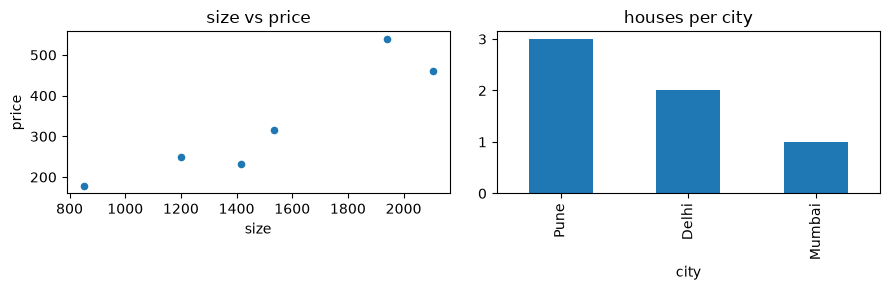

In [38]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
df.plot.scatter(x="size", y="price", ax=ax[0], title="size vs price")
df["city"].value_counts().plot.bar(ax=ax[1], title="houses per city")
plt.tight_layout()
plt.show()

## 17. Cheat sheet

| Task | Code |
|---|---|
| Make a table | `pd.DataFrame({"col": [...], ...})` |
| Read / save CSV | `pd.read_csv("f.csv")`, `df.to_csv("f.csv", index=False)` |
| First look | `df.head()`, `df.shape`, `df.info()`, `df.describe()` |
| One column / several | `df["a"]`, `df[["a", "b"]]` |
| Rows by position / label | `df.iloc[0]`, `df.iloc[1:3]`, `df.loc[0, "a"]` |
| Filter | `df[df["a"] > 5]`, `df[(cond1) & (cond2)]`, `df[df["a"].isin([...])]` |
| New column | `df["c"] = df["a"] * df["b"]` |
| Rename / remove | `df.rename(columns={"a": "b"})`, `df.drop(columns=["a"])` |
| Sort | `df.sort_values("a", ascending=False)` |
| Missing values | `df.isna().sum()`, `df.dropna()`, `df["a"].fillna(v)` |
| Count values | `df["a"].value_counts()`, `df["a"].nunique()` |
| Group and summarize | `df.groupby("a")["b"].mean()`, `.agg(["mean", "max"])` |
| Text to numbers | `s.map({...})`, `pd.get_dummies(df, columns=["a"], dtype=int)` |
| Own function per value | `df["a"].apply(func)` |
| Stack / join tables | `pd.concat([df1, df2])`, `pd.merge(df1, df2, on="key")` |
| To NumPy | `df[features].to_numpy()`, `df["y"].to_numpy()` |

**Practice:** using `df`, find the average `age` of houses with more than 2 bedrooms, then make `X` from the `size` and `age` columns.

In [39]:
# your code here